# Basic Statistics: Hypothesis Testing Case Study
**Author:** Amal Shesnij

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

loans = pd.read_csv('LoansData.csv')
print(loans.shape)
loans.head()

(2500, 14)


,Amount.Requested,Amount.Funded.By.Investors,Interest.Rate,Loan.Length,Loan.Purpose,Debt.To.Income.Ratio,State,Home.Ownership,Monthly.Income,FICO.Range,Open.CREDIT.Lines,Revolving.CREDIT.Balance,Inquiries.in.the.Last.6.Months,Employment.Length
0,20000.0,20000.0,8.90%,36 months,debt_consolidation,14.90%,SC,MORTGAGE,6541.67,735-739,14.0,14272.0,2.0,< 1 year
1,19200.0,19200.0,12.12%,36 months,debt_consolidation,28.36%,TX,MORTGAGE,4583.33,715-719,12.0,11140.0,1.0,2 years
2,35000.0,35000.0,21.98%,60 months,debt_consolidation,23.81%,CA,MORTGAGE,11500.00,690-694,14.0,21977.0,1.0,2 years
3,10000.0,9975.0,9.99%,36 months,debt_consolidation,14.30%,KS,MORTGAGE,3833.33,695-699,10.0,9346.0,0.0,5 years
4,12000.0,12000.0,11.71%,36 months,credit_card,18.78%,NJ,RENT,3195.00,695-699,11.0,14469.0,0.0,9 years


## Problem 1: Lending Club loans

### Data cleaning

In [2]:
# Remove "%" and convert to numbers
loans['Interest.Rate'] = loans['Interest.Rate'].str.rstrip('%').astype(float)
loans['Debt.To.Income.Ratio'] = loans['Debt.To.Income.Ratio'].str.rstrip('%').astype(float)

# "36 months" -> 36
loans['Loan.Length'] = loans['Loan.Length'].str.extract(r'(\d+)').astype(float)

# "735-739" -> 735 (lower end of the range)
loans['FICO'] = loans['FICO.Range'].str.split('-').str[0].astype(float)

print(loans[['Interest.Rate', 'Loan.Length', 'FICO', 'Debt.To.Income.Ratio']].dtypes)
print('\nMissing values:')
print(loans.isnull().sum()[loans.isnull().sum() > 0])

Interest.Rate           float64
Loan.Length             float64
FICO                    float64
Debt.To.Income.Ratio    float64
dtype: object

Missing values:
Amount.Requested                   1
Amount.Funded.By.Investors         1
Interest.Rate                      2
Debt.To.Income.Ratio               1
Home.Ownership                     1
Monthly.Income                     1
FICO.Range                         2
Open.CREDIT.Lines                  3
Revolving.CREDIT.Balance           3
Inquiries.in.the.Last.6.Months     3
Employment.Length                 77
FICO                               2
dtype: int64


### 1a. Interest rate vs loan amount

Correlation r = 0.332
p-value       = 1.58e-65


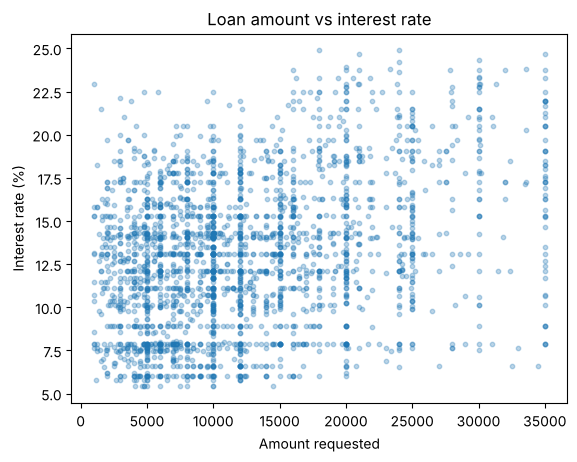

In [3]:
d = loans.dropna(subset=['Amount.Requested', 'Interest.Rate'])

r, p = stats.pearsonr(d['Amount.Requested'], d['Interest.Rate'])
print(f'Correlation r = {r:.3f}')
print(f'p-value       = {p:.2e}')

plt.scatter(d['Amount.Requested'], d['Interest.Rate'], alpha=0.3, s=10)
plt.xlabel('Amount requested'); plt.ylabel('Interest rate (%)')
plt.title('Loan amount vs interest rate')
plt.show()

**Conclusion (1a):**
The p-value is almost zero (less than 0.05), so the result is real and not by chance. The correlation is +0.33, which means when the loan amount goes up, the interest rate also goes up. So the claim "bigger loans get less interest" is **not true**. In this data, bigger loans actually get slightly higher interest, probably because they are riskier for the lender.

### 1b. Interest rate vs loan length

              mean  count
Loan.Length              
36.0         12.13   1950
60.0         16.41    548

t = -21.95,  p-value = 3.93e-84


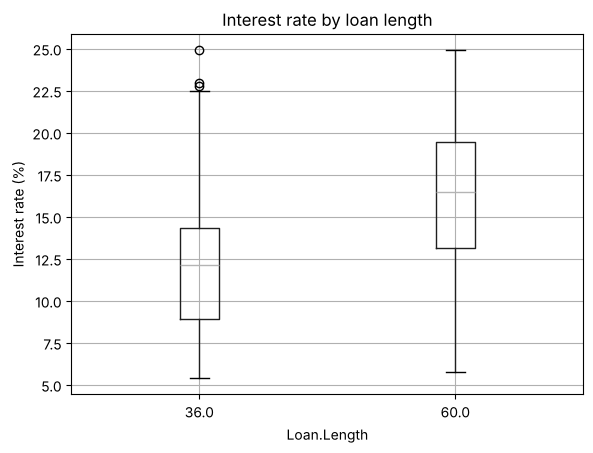

In [4]:
print(loans.groupby('Loan.Length')['Interest.Rate'].agg(['mean', 'count']).round(2))

short = loans.loc[loans['Loan.Length'] == 36, 'Interest.Rate'].dropna()
long_ = loans.loc[loans['Loan.Length'] == 60, 'Interest.Rate'].dropna()

t, p = stats.ttest_ind(short, long_, equal_var=False)
print(f'\nt = {t:.2f},  p-value = {p:.2e}')

loans.boxplot(column='Interest.Rate', by='Loan.Length')
plt.title('Interest rate by loan length'); plt.suptitle('')
plt.ylabel('Interest rate (%)'); plt.show()

**Conclusion (1b):**
The p-value is almost zero (less than 0.05), so the difference is real. 60-month loans have an average interest rate of 16.41%, compared with 12.13% for 36-month loans. So loan length **does affect** the interest rate: longer loans are charged about 4.3 percentage points more, probably because the lender's money is at risk for longer.

### 1c. Interest rate vs loan purpose

In [5]:
purpose = (loans.groupby('Loan.Purpose')['Interest.Rate']
                .agg(['mean', 'count']).round(2).sort_values('mean'))
print(purpose)

groups = [g.dropna() for _, g in loans.groupby('Loan.Purpose')['Interest.Rate']]
f, p = stats.f_oneway(*groups)
print(f'\nF = {f:.2f},  p-value = {p:.2e}')

                     mean  count
Loan.Purpose                    
renewable_energy     9.88      4
major_purchase      10.80    101
educational         11.01     15
car                 11.11     50
home_improvement    11.59    152
medical             11.65     30
vacation            11.97     21
wedding             12.05     38
small_business      12.84     87
credit_card         13.05    443
other               13.16    201
house               13.45     20
debt_consolidation  13.59   1307
moving              13.62     29

F = 7.48,  p-value = 1.17e-14


**Conclusion (1c):**
The p-value is almost zero (less than 0.05), so interest rates **do vary** by loan purpose. Debt consolidation loans (the largest group, 1,307 loans) average 13.59%, while major purchase loans average 10.80%. Some purposes, such as renewable energy (4 loans), have too few loans to draw reliable conclusions.

### 1d. FICO score vs home ownership

                 mean  count
Home.Ownership              
MORTGAGE        711.7   1146
OWN             706.6    200
RENT            700.1   1145

F = 32.50,  p-value = 1.16e-14


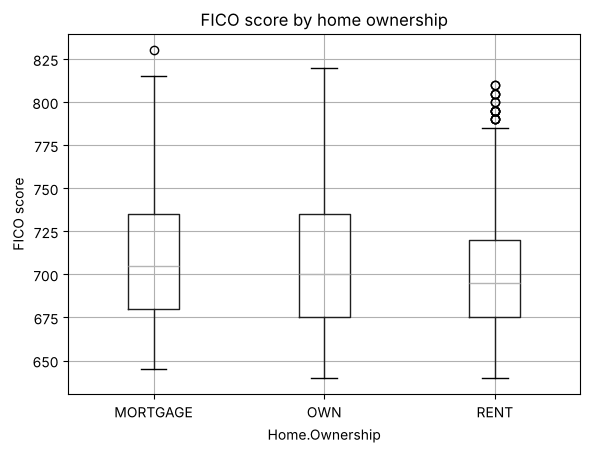

In [6]:
# Keep the 3 main groups (OTHER and NONE have only 6 loans in total)
home = loans[loans['Home.Ownership'].isin(['MORTGAGE', 'OWN', 'RENT'])]

print(home.groupby('Home.Ownership')['FICO'].agg(['mean', 'count']).round(1))

groups = [g.dropna() for _, g in home.groupby('Home.Ownership')['FICO']]
f, p = stats.f_oneway(*groups)
print(f'\nF = {f:.2f},  p-value = {p:.2e}')

home.boxplot(column='FICO', by='Home.Ownership')
plt.title('FICO score by home ownership'); plt.suptitle('')
plt.ylabel('FICO score'); plt.show()

**Conclusion (1d):**
The p-value is almost zero (less than 0.05), so FICO scores **do differ** by home ownership. However, the claim is only partly true: people with a **mortgage** have the highest average FICO score (711.7), then people who fully own their home (706.6), then renters (700.1). Home-related borrowers do score higher than renters, but the differences are small (about 5–12 points). The OTHER and NONE groups (6 loans in total) were excluded as too small to compare.

## Problem 2: Price quotes (Mary vs Barry)

In [7]:
quotes = pd.read_csv('Price_Quotes.csv')
quotes['Difference'] = quotes['Barry_Price'] - quotes['Mary_Price']
print(quotes)
print('\nAverage quote:', quotes[['Barry_Price', 'Mary_Price']].mean().round(2).to_dict())

t, p = stats.ttest_rel(quotes['Barry_Price'], quotes['Mary_Price'])
print(f'\nt = {t:.2f},  p-value = {p:.4f}')

    Order_Number  Barry_Price  Mary_Price  Difference
0              1          126         114          12
1              2          110         118          -8
2              3          138         114          24
3              4          142         111          31
4              5          146         129          17
5              6          136         119          17
6              7           94          97          -3
7              8          103         104          -1
8              9          140         127          13
9             10          152         133          19
10            11          108         103           5
11            12           97         108         -11

Average quote: {'Barry_Price': 124.33, 'Mary_Price': 114.75}

t = 2.52,  p-value = 0.0284


**Conclusion (Problem 2):**
The p-value is 0.028, which is less than 0.05, so the difference is real. For the same 12 orders, Barry's average quote (124.33) is about 9.6 higher than Mary's (114.75). So the two pricing experts **do give different prices**, which confirms the manager's concern about inconsistent pricing. A paired t-test was used because both experts priced the same orders.

## Problem 3: Treatment facility reengineering

In [8]:
facility = pd.read_csv('Treatment_Facility.csv')
facility = facility.rename(columns={'VAR4': 'TRFF', 'VAR5': 'CI'})

print(facility.groupby('Reengineer')[['Employee_Turnover', 'TRFF', 'CI']].mean().round(2))
print()

for col in ['Employee_Turnover', 'TRFF', 'CI']:
    prior = facility.loc[facility['Reengineer'] == 'Prior', col]
    post = facility.loc[facility['Reengineer'] == 'Post', col]
    t, p = stats.ttest_ind(prior, post, equal_var=False)
    print(f'{col:18}  p-value = {p:.4f}')

            Employee_Turnover   TRFF     CI
Reengineer                                 
Post                    18.69   9.23  23.35
Prior                   11.74  20.54  53.89

Employee_Turnover   p-value = 0.1521
TRFF                p-value = 0.0023
CI                  p-value = 0.0456


**Conclusion (Problem 3):**
The reengineering program **reduced behavioural problems**: the critical incident rate fell from 53.89% to 23.35% (p = 0.046), and residents removed from the facility fell from 20.54% to 9.23% (p = 0.002). Both p-values are below 0.05, so these improvements are real.
However, employee turnover **did not improve**. It rose from 11.74% to 18.69%, but the p-value (0.152) is above 0.05, so this change is not statistically proven.
Note: the columns VAR4 and VAR5 were taken as TRFF and CI, following the order in the case description. Only 7 months of post-program data are available, so results should be confirmed with more data.

## Problem 4: Job priority vs completion time

          mean  median  count
Priority                     
High      3.02     0.6    326
Low       4.23     1.2     67
Medium    2.50     0.5    249

ANOVA:           p-value = 0.1641
Kruskal-Wallis:  p-value = 0.0303


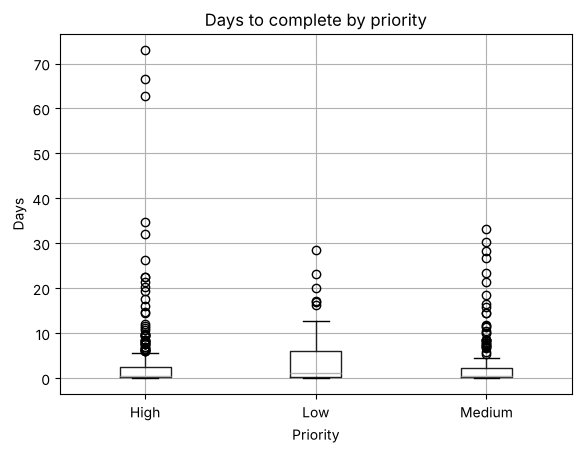

In [9]:
jobs = pd.read_csv('Priority_Assessment.csv')

print(jobs.groupby('Priority')['Days'].agg(['mean', 'median', 'count']).round(2))

groups = [g for _, g in jobs.groupby('Priority')['Days']]
f, p = stats.f_oneway(*groups)
print(f'\nANOVA:           p-value = {p:.4f}')

h, p2 = stats.kruskal(*groups)
print(f'Kruskal-Wallis:  p-value = {p2:.4f}')

jobs.boxplot(column='Days', by='Priority')
plt.title('Days to complete by priority'); plt.suptitle('')
plt.ylabel('Days'); plt.show()

**Conclusion (Problem 4):**
The completion times are very skewed (most jobs take less than 1 day, but a few take over 60), so the Kruskal-Wallis test is more reliable than ANOVA here. Kruskal-Wallis gives p = 0.03 (less than 0.05), so the priority groups do differ, mainly because low-priority jobs take longer (median 1.2 days).
However, the prioritisation system is **not working as intended**: high-priority jobs (median 0.6 days, mean 3.02) are **not faster** than medium-priority jobs (median 0.5 days, mean 2.50). The project manager should review why high-priority jobs are not being completed first.

## Problem 5: Film on the Rocks survey

In [10]:
films = pd.read_csv('Films.csv')
print(films.shape)
print(films['Gender'].value_counts(dropna=False))
print(films['Marital_Status'].value_counts(dropna=False))

(330, 11)
Gender
2         194
1         104
Female     19
Male       13
Name: count, dtype: int64
Marital_Status
2          208
1           88
Single      18
Married     12
Slngle       2
NaN          2
Name: count, dtype: int64


In [11]:
films['Gender'] = films['Gender'].replace({'1': 'Male', '2': 'Female'})
films['Marital_Status'] = films['Marital_Status'].replace(
    {'1': 'Married', '2': 'Single', 'Slngle': 'Single'})

print(films['Gender'].value_counts(dropna=False))
print(films['Marital_Status'].value_counts(dropna=False))

Gender
Female    213
Male      117
Name: count, dtype: int64
Marital_Status
Single     228
Married    100
NaN          2
Name: count, dtype: int64


### 5a. Overall satisfaction

In [12]:
ratings = ['Sinage', 'Parking', 'Clean', 'Overall']
print('Average rating (1 = Excellent, 5 = Very Poor):')
print(films[ratings].mean().round(2))

labels = {1: 'Excellent', 2: 'Good', 3: 'Average', 4: 'Poor', 5: 'Very Poor'}
overall = films['Overall'].map(labels).value_counts(normalize=True) * 100
print('\nOverall experience (%):')
print(overall.round(1))

Average rating (1 = Excellent, 5 = Very Poor):
Sinage     1.88
Parking    1.76
Clean      1.68
Overall    1.62
dtype: float64

Overall experience (%):
Overall
Good         48.8
Excellent    46.0
Average       3.7
Very Poor     1.2
Poor          0.3
Name: proportion, dtype: float64


**Conclusion (5a):** Satisfaction is very high. The average overall rating is 1.62 on a scale where 1 = Excellent and 5 = Very Poor. About 46% of patrons rated their experience Excellent and 49% rated it Good, so roughly 95% were satisfied.

### 5b. Factors linked to satisfaction

In [13]:
for col in ['Sinage', 'Parking', 'Clean']:
    d = films[[col, 'Overall']].dropna()
    r, p = stats.spearmanr(d[col], d['Overall'])
    print(f'{col:8}  r = {r:.2f},  p-value = {p:.2e}')

print()
for col in ['Gender', 'Marital_Status', 'Movie']:
    print(films.groupby(col)['Overall'].mean().round(2), '\n')

Sinage    r = 0.46,  p-value = 3.53e-18
Parking   r = 0.54,  p-value = 5.07e-26
Clean     r = 0.43,  p-value = 2.50e-16

Gender
Female    1.58
Male      1.69
Name: Overall, dtype: float64 

Marital_Status
Married    1.58
Single     1.64
Name: Overall, dtype: float64 

Movie
Ferris Buellers Day Off    1.66
Old School                 1.44
Willy Wonka                1.62
Name: Overall, dtype: float64 



**Conclusion (5b):** All three venue factors are linked to overall satisfaction (all p-values are almost zero). **Parking has the strongest link** (Spearman r = 0.54), followed by signage (0.46) and cleanliness (0.43). Gender, marital status and the movie shown make little difference to the overall rating. Improving parking is the best way to raise satisfaction further.

### 5c. Demographic profile

In [14]:
age_labels = {1: '1-12', 2: '13-30', 3: '31-60', 4: '60+'}
income_labels = {1: 'Under $50K', 2: '$50K-$100K', 3: 'Over $100K'}

print((films['Gender'].value_counts(normalize=True) * 100).round(1), '\n')
print((films['Marital_Status'].value_counts(normalize=True) * 100).round(1), '\n')
print((films['Age'].map(age_labels).value_counts(normalize=True) * 100).round(1), '\n')
print((films['Income'].map(income_labels).value_counts(normalize=True) * 100).round(1))

Gender
Female    64.5
Male      35.5
Name: proportion, dtype: float64 

Marital_Status
Single     69.5
Married    30.5
Name: proportion, dtype: float64 

Age
13-30    53.4
31-60    35.7
1-12      7.9
60+       3.0
Name: proportion, dtype: float64 

Income
Under $50K    45.2
Over $100K    28.7
$50K-$100K    26.1
Name: proportion, dtype: float64


**Conclusion (5c):** The typical patron is female (about 65%), single (about 70%) and aged 13–30 (about 53%), with a further 36% aged 31–60. Incomes are mixed: about 45% earn under $50K, and about 29% earn over $100K. This young, mostly single audience is useful information for attracting sponsors who target that group.

### 5d. Best advertising channel

Hear_About
Word of mouth    71.8
Website          13.9
Television        7.1
Radio             5.3
Newspaper         4.3
Name: count, dtype: float64


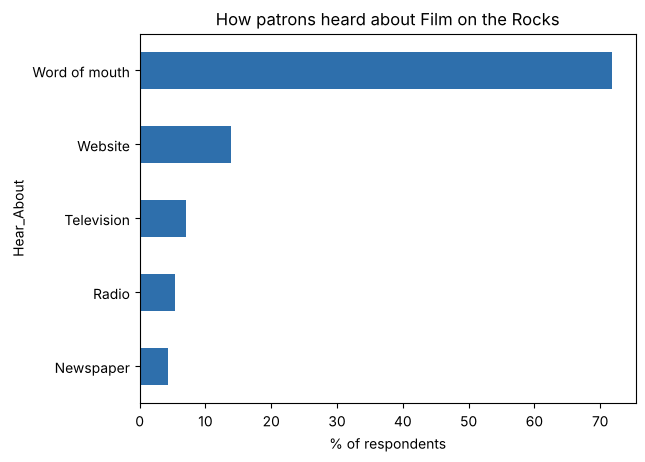

In [15]:
media = {'1': 'Television', '2': 'Newspaper', '3': 'Radio', '4': 'Website', '5': 'Word of mouth'}

answers = films['Hear_About'].dropna().str.split(',').explode().str.strip()
channel = answers.map(media).value_counts()
channel_pct = (channel / films['Hear_About'].notna().sum() * 100).round(1)
print(channel_pct)

channel_pct.sort_values().plot(kind='barh', color='#2E6FAC')
plt.xlabel('% of respondents'); plt.title('How patrons heard about Film on the Rocks')
plt.show()

**Conclusion (5d):** Word of mouth is by far the main channel: about 72% of respondents heard about the series this way, followed by the website (about 14%). Television, radio and newspapers each reach under 8%. The promoters should invest in word-of-mouth and online marketing (social media, referral offers, the website) rather than traditional media.

## Key Findings

**Problem 1: Lending Club loans**
- Larger loans carry **higher** interest rates (r = 0.33, p < 0.05), the opposite of the claim.
- 60-month loans average 16.41% vs 12.13% for 36-month loans (p < 0.05).
- Interest rates differ by loan purpose (ANOVA p < 0.05).
- Mortgage holders have the highest FICO scores (711.7), ahead of full owners (706.6) and renters (700.1), so the claim is only partly true.

**Problem 2: Price quotes**
- Barry quotes about 9.6 higher than Mary on the same orders (paired t-test, p = 0.028), so pricing is inconsistent between experts.

**Problem 3: Treatment facility**
- Critical incidents fell from 53.9% to 23.4% (p = 0.046) and removals from 20.5% to 9.2% (p = 0.002).
- Employee turnover did not improve (11.7% to 18.7%, p = 0.15, not significant).

**Problem 4: Job prioritisation**
- High-priority jobs are **not** completed faster than medium-priority jobs, so the system is not working as intended.

**Problem 5: Film on the Rocks**
- About 95% of patrons rate their experience Good or Excellent.
- Parking is the factor most linked to satisfaction (r = 0.54).
- Typical patron: female, single, aged 13–30.
- Word of mouth reaches about 72% of patrons, so it should be the focus of marketing.

## Assumptions
- A significance level of 0.05 was used for all tests.
- Rows with missing values were excluded from each test.
- OTHER and NONE home ownership (6 loans) were excluded as too small to compare.
- VAR4 and VAR5 were taken as TRFF and CI, following the order in the case description.
- Spearman correlation and Kruskal-Wallis were used where data was ranked or highly skewed.